In [2]:
import os



def verifier_extensions(dossier):
    extensions = [".jpg", ".png", ".bmp",".jpeg"]
    invalides = []

    for racine, dossiers, fichiers in os.walk(dossier):
        for fichier in fichiers:
            ext = os.path.splitext(fichier)[1].lower()

            if ext not in extensions:
                path = os.path.join(racine, fichier)
                invalides.append(path)

    return invalides

res = verifier_extensions('../Data')

for e in res:
    os.remove(e)
    print("Supprimé :", e)




In [ ]:
import cv2

path='../Data'
imgs=[]
labels=[]

for cls in os.listdir(path):
    cls_path=os.path.join(path,cls)

    if os.path.isdir(cls_path):
        for file in os.listdir(cls_path):
            pat=os.path.join(cls_path,file)

            try:
                image=cv2.imread(pat)

                if image is not None:
                    image=cv2.resize(image,(64,64))

                    imgs.append(image)
                    labels.append(cls)
            except Exception as e:
                print('erreur :',path,e)




In [17]:
from collections import Counter

compteur = Counter(labels)

compteur

Counter({'notumor': 2000,
         'pituitary': 1757,
         'meningioma': 1645,
         'glioma': 1621})

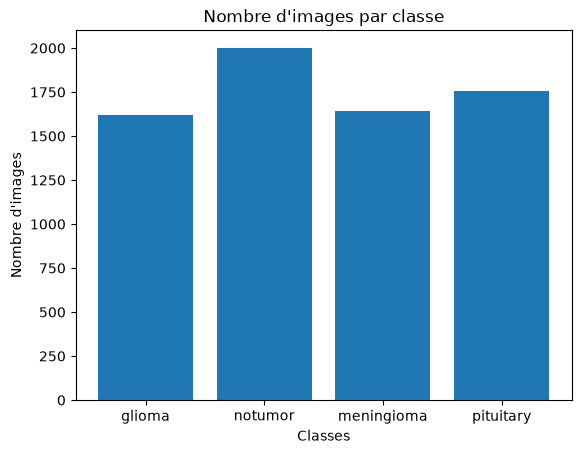

In [18]:
import matplotlib.pyplot as plt

plt.bar(compteur.keys(), compteur.values())
plt.xlabel("Classes")
plt.ylabel("Nombre d'images")
plt.title("Nombre d'images par classe")
plt.show()

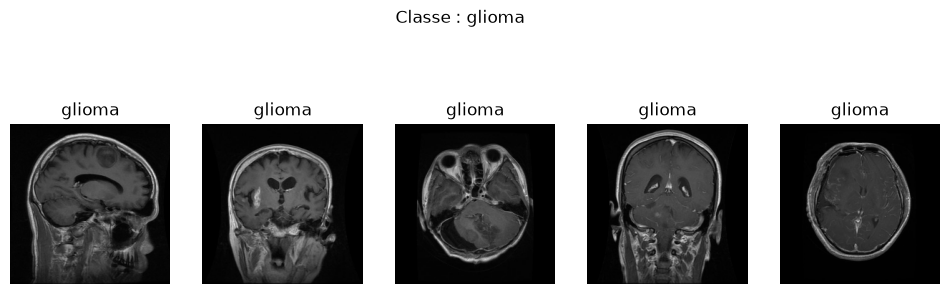

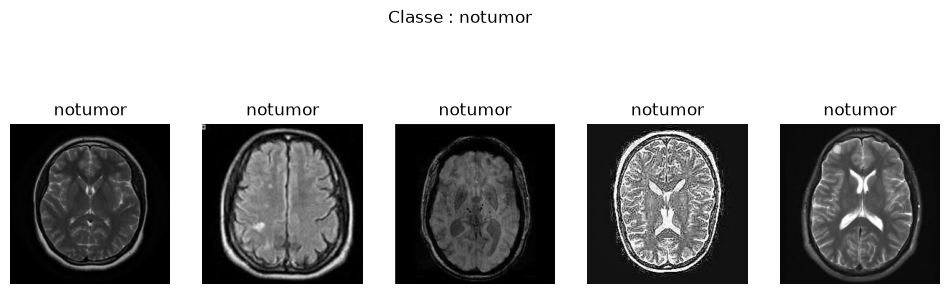

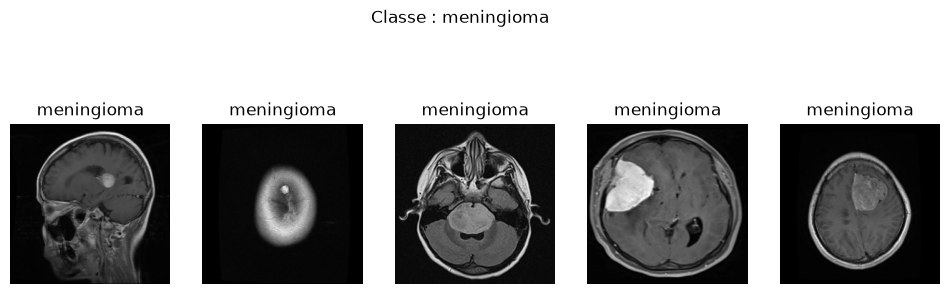

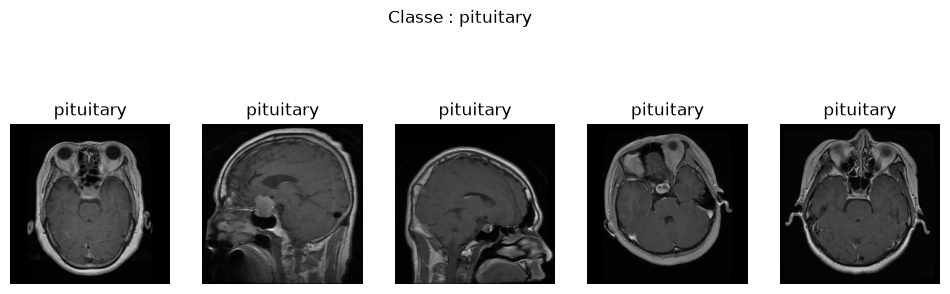

In [19]:
import matplotlib.pyplot as plt
import random

for classe in set(labels):
    indices = [i for i in range(len(labels)) if labels[i] == classe]
    indices = random.sample(indices, min(5, len(indices)))

    plt.figure(figsize=(12, 4))

    for i, index in enumerate(indices):
        plt.subplot(1, 5, i + 1)
        plt.imshow(imgs[index][:, :, ::-1])
        plt.title(labels[index])
        plt.axis("off")

    plt.suptitle("Classe : " + classe)
    plt.show()

In [20]:
from sklearn.preprocessing import LabelEncoder

prep = LabelEncoder()

lbs = prep.fit_transform(labels)
lbs

array([0, 0, 0, ..., 3, 3, 3], shape=(7023,))

In [ ]:
from sklearn.model_selection import train_test_split
import numpy as np
x_train,x_test,y_train,y_test = train_test_split(
    imgs,
    lbs,
    test_size=0.2,
    random_state=42,
    stratify=lbs
)

x_train = np.array(x_train,dtype=np.float32)
x_test = np.array(x_test,dtype=np.float32)
